1 — Paths + experiment settings

In [1]:
import os, json, time, subprocess, re
from pathlib import Path

THESIS_ROOT = Path("/home/psivakumar/thesis")
R2GEN_DIR   = THESIS_ROOT / "code" / "R2GenCMN"

# Data
ANN_PATH = THESIS_ROOT / "data" / "iu_xray" / "annotation_r2gencmn_2view_r2gencmnformat.json"
IMG_DIR  = R2GEN_DIR / "data" / "iu_xray"   # contains images/ symlink

assert R2GEN_DIR.exists(), f"Missing repo: {R2GEN_DIR}"
assert ANN_PATH.exists(), f"Missing annotation: {ANN_PATH}"
assert (IMG_DIR / "images").exists(), f"Missing images symlink at: {IMG_DIR/'images'}"

TUNE_OUT = R2GEN_DIR / "outputs" / "tuning_iu_xray_r2gencmn"
TUNE_REC = R2GEN_DIR / "records" / "tuning_iu_xray_r2gencmn"
TUNE_OUT.mkdir(parents=True, exist_ok=True)
TUNE_REC.mkdir(parents=True, exist_ok=True)

# ---- Tuning controls ----
FAST_MODE = True
BASE_EPOCHS = 3 if FAST_MODE else 10

print("Repo:", R2GEN_DIR)
print("ANN :", ANN_PATH)
print("IMG :", IMG_DIR)
print("FAST_MODE:", FAST_MODE, "| BASE_EPOCHS:", BASE_EPOCHS)
print("OUT :", TUNE_OUT)
print("REC :", TUNE_REC)

Repo: /home/psivakumar/thesis/code/R2GenCMN
ANN : /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json
IMG : /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray
FAST_MODE: True | BASE_EPOCHS: 3
OUT : /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn
REC : /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn


2 — Detect which CLI flags main.py supports

2 — Detect which CLI flags main.py supports (so commands won’t break)

In [2]:
main_py = (R2GEN_DIR / "main.py").read_text()

flags = sorted(set(re.findall(r"--[a-zA-Z0-9_\-]+", main_py)))

print("Detected flags in main.py (first 60):")
for f in flags[:60]:
    print(" ", f)
print("\nTotal flags found:", len(flags))

SUPPORTED = set(flags)

def add_arg(cmd_list, flag, value):
    """Add a CLI flag only if it exists in main.py"""
    if flag in SUPPORTED:
        cmd_list += [flag, str(value)]
    return cmd_list

print("\nExample check: --batch_size supported?", "--batch_size" in SUPPORTED)

✅ Detected flags in main.py (first 60):
  --adam_betas
  --adam_eps
  --amsgrad
  --ann_path
  --batch_size
  --beam_size
  --block_trigrams
  --bos_idx
  --cmm_dim
  --cmm_size
  --d_ff
  --d_model
  --d_vf
  --dataset_name
  --decoding_constraint
  --drop_prob_lm
  --dropout
  --early_stop
  --eos_idx
  --epochs
  --gamma
  --group_size
  --image_dir
  --log_period
  --logit_layers
  --lr_ed
  --lr_scheduler
  --lr_ve
  --max_seq_length
  --monitor_metric
  --monitor_mode
  --n_gpu
  --noamopt_factor
  --noamopt_warmup
  --num_heads
  --num_layers
  --num_workers
  --optim
  --output_logsoftmax
  --pad_idx
  --record_dir
  --resume
  --sample_method
  --sample_n
  --save_dir
  --save_period
  --seed
  --step_size
  --temperature
  --threshold
  --topk
  --use_bn
  --visual_extractor
  --visual_extractor_pretrained
  --weight_decay

Total flags found: 55

Example check: --batch_size supported? True


3 — ROUGE-L (pure python) + helper metrics

In [3]:
from collections import Counter
import numpy as np

def lcs(a, b):
    n, m = len(a), len(b)
    dp = [[0]*(m+1) for _ in range(n+1)]
    for i in range(n):
        for j in range(m):
            if a[i] == b[j]:
                dp[i+1][j+1] = dp[i][j] + 1
            else:
                dp[i+1][j+1] = max(dp[i][j+1], dp[i+1][j])
    return dp[n][m]

def rouge_l_f1(pred, ref):
    pred_tokens = pred.lower().split()
    ref_tokens  = ref.lower().split()
    if not pred_tokens or not ref_tokens:
        return 0.0
    l = lcs(pred_tokens, ref_tokens)
    prec = l / len(pred_tokens)
    rec  = l / len(ref_tokens)
    return 0.0 if (prec + rec) == 0 else (2 * prec * rec / (prec + rec))

def word_count(s): 
    return len([w for w in s.strip().split() if w])

def summarize_texts(texts):
    texts = [t.strip() for t in texts]
    uniq = len(set(texts))
    top = Counter(texts).most_common(1)[0]
    lengths = [word_count(t) for t in texts]
    return {
        "count": len(texts),
        "unique": uniq,
        "avg_words": float(np.mean(lengths)) if lengths else 0.0,
        "top_pred_freq": int(top[1]),
        "top_pred_preview": top[0][:140]
    }

print("ROUGE-L + text summary utils ready")

✅ ROUGE-L + text summary utils ready


4 — Build VAL loader + inference (standalone, no trainer imports)

In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

# Ensure repo imports work
import sys
sys.path.insert(0, str(R2GEN_DIR))

from modules.tokenizers import Tokenizer
from modules.datasets import IuxrayMultiImageDataset
from models.models import BaseCMNModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# transform needed because dataset stacks tensors
img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

def r2gen_collate_fn(batch):
    image_ids, images, report_ids, report_masks, seq_lengths = zip(*batch)
    images = torch.stack(images, dim=0)

    max_len = max(seq_lengths)
    padded_ids   = torch.zeros(len(report_ids), max_len, dtype=torch.long)
    padded_masks = torch.zeros(len(report_masks), max_len, dtype=torch.long)

    for i, (ids, masks) in enumerate(zip(report_ids, report_masks)):
        ids_t   = torch.tensor(ids, dtype=torch.long)
        masks_t = torch.tensor(masks, dtype=torch.long)
        padded_ids[i, :len(ids_t)] = ids_t
        padded_masks[i, :len(masks_t)] = masks_t

    return list(image_ids), images, padded_ids, padded_masks, torch.tensor(seq_lengths)

print("Data pipeline utilities ready")

Device: cuda
✅ Data pipeline utilities ready


5 — “Args builder” for inference (kept consistent across runs)

In [5]:
class Args:
    dataset_name = "iu_xray"
    ann_path = str(ANN_PATH)
    image_dir = str(IMG_DIR)
    threshold = 3
    max_seq_length = 100
    num_workers = 0

    # visual
    visual_extractor = "resnet101"
    visual_extractor_pretrained = True
    d_vf = 2048

    # model
    d_model = 512
    d_ff = 512
    num_layers = 3
    num_heads = 8
    dropout = 0.1
    drop_prob_lm = 0.1
    use_bn = False

    # CMN
    topk = 32
    cmm_size = 2048
    cmm_dim  = 512

    # decoding
    beam_size = 1
    sample_method = "greedy"
    temperature = 1.0

    # placeholders
    monitor_metric = "BLEU_4"
    monitor_mode = "max"
    early_stop = 0
    save_period = 1

def make_args_for_inference(dropout_val=0.1):
    args = Args()
    # tie dropout fields
    args.dropout = float(dropout_val)
    args.drop_prob_lm = float(dropout_val)

    args.pad_idx = 0
    args.bos_idx = 0
    args.eos_idx = 0
    args.unk_idx = 27
    return args

print("Args builder ready")

✅ Args builder ready


6 — Evaluation function (loads checkpoint → generates VAL preds → ROUGE-L)

In [6]:
def evaluate_checkpoint(ckpt_path, dropout_val=0.1, max_batches=None):
    ckpt_path = Path(ckpt_path)
    assert ckpt_path.exists(), f"Missing checkpoint: {ckpt_path}"

    args = make_args_for_inference(dropout_val=dropout_val)
    tokenizer = Tokenizer(args)

    val_ds = IuxrayMultiImageDataset(args=args, tokenizer=tokenizer, split="val", transform=img_transform)
    val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=0, collate_fn=r2gen_collate_fn)

    model = BaseCMNModel(args, tokenizer).to(DEVICE)
    ckpt = torch.load(str(ckpt_path), map_location=DEVICE)
    state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
    model.load_state_dict(state_dict, strict=False)
    model.eval()

    preds, gts, uids = [], [], []

    with torch.no_grad():
        for bi, batch in enumerate(val_loader):
            image_ids, images, report_ids, report_masks, seq_lengths = batch
            images = images.to(DEVICE)

            outputs = model(images, mode="sample")
            out_ids = outputs[0] if isinstance(outputs, tuple) else outputs

            batch_preds = tokenizer.decode_batch(out_ids.cpu().numpy())
            batch_gts   = tokenizer.decode_batch(report_ids[:, 1:].cpu().numpy())

            preds.extend([p.strip() for p in batch_preds])
            gts.extend([t.strip() for t in batch_gts])
            uids.extend([str(x) for x in image_ids])

            if max_batches is not None and (bi + 1) >= max_batches:
                break

    rouge_scores = [rouge_l_f1(p, r) for p, r in zip(preds, gts)]
    met = {
        "val_count": len(preds),
        "rougeL_mean": float(np.mean(rouge_scores)) if rouge_scores else 0.0,
        "rougeL_std": float(np.std(rouge_scores)) if rouge_scores else 0.0,
        "pred_summary": summarize_texts(preds),
        "gt_summary": summarize_texts(gts),
    }
    out_preds = [{"uid": u, "ground_truth": gt, "prediction": pr} for u, gt, pr in zip(uids, gts, preds)]
    return met, out_preds

print("Evaluation function ready")

✅ Evaluation function ready


7 — Training runner (calls python main.py ... safely)

In [7]:
def run_training_trial(run_name, epochs, batch_size, lr=None, dropout=None, resume=None):
    save_dir   = TUNE_OUT / run_name
    record_dir = TUNE_REC / run_name
    save_dir.mkdir(parents=True, exist_ok=True)
    record_dir.mkdir(parents=True, exist_ok=True)

    cmd = ["python", "main.py",
           "--dataset_name", "iu_xray",
           "--image_dir", str(IMG_DIR),
           "--ann_path", str(ANN_PATH),
           "--save_dir", str(save_dir),
           "--record_dir", str(record_dir),
           "--epochs", str(epochs),
           "--batch_size", str(batch_size)]

    if lr is not None:
        cmd = add_arg(cmd, "--lr", lr)
        cmd = add_arg(cmd, "--learning_rate", lr)
    if dropout is not None:
        cmd = add_arg(cmd, "--drop_prob_lm", dropout)
        cmd = add_arg(cmd, "--dropout", dropout)

    if resume is not None:
        cmd += ["--resume", str(resume)]

    print("\n=== Running trial ===")
    print("Run:", run_name)
    print("CMD:", " ".join(cmd))

    t0 = time.time()
    p = subprocess.run(cmd, cwd=str(R2GEN_DIR), capture_output=True, text=True)
    dt = time.time() - t0

    # Print last lines for notebook evidence
    print("\n--- stdout (last 30 lines) ---")
    print("\n".join(p.stdout.splitlines()[-30:]))
    print("\n--- stderr (last 10 lines) ---")
    print("\n".join(p.stderr.splitlines()[-10:]))

    print("\nReturn code:", p.returncode, "| time(s):", round(dt, 1))

    ckpt = save_dir / "current_checkpoint.pth"
    ckpt_exists = ckpt.exists()
    print("Checkpoint:", ckpt, "| exists:", ckpt_exists)

    return {"run_name": run_name, "save_dir": str(save_dir), "record_dir": str(record_dir),
            "returncode": p.returncode, "seconds": dt, "checkpoint": str(ckpt) if ckpt_exists else None}

8 — Define the tuning plan (minimal + defensible)

In [8]:
# - LR: 1e-4 vs 5e-5 vs 1e-5
# - Dropout: 0.1 vs 0.3
# - Batch size: 4 vs 8

TUNING_TRIALS = []

# baseline reference
TUNING_TRIALS.append({"name": "baseline_lr1e-4_do0.1_bs8", "lr": 1e-4, "dropout": 0.1, "bs": 8})

# learning rate (keep dropout=0.1, bs=8)
TUNING_TRIALS += [
    {"name": "lr5e-5_do0.1_bs8", "lr": 5e-5, "dropout": 0.1, "bs": 8},
    {"name": "lr1e-5_do0.1_bs8", "lr": 1e-5, "dropout": 0.1, "bs": 8},
]

# dropout (keep lr=1e-4, bs=8)
TUNING_TRIALS += [
    {"name": "lr1e-4_do0.3_bs8", "lr": 1e-4, "dropout": 0.3, "bs": 8},
]

# batch size (keep lr=1e-4, dropout=0.1)
TUNING_TRIALS += [
    {"name": "lr1e-4_do0.1_bs4", "lr": 1e-4, "dropout": 0.1, "bs": 4},
]

print("Total trials:", len(TUNING_TRIALS))
for t in TUNING_TRIALS:
    print(t)

Total trials: 5
{'name': 'baseline_lr1e-4_do0.1_bs8', 'lr': 0.0001, 'dropout': 0.1, 'bs': 8}
{'name': 'lr5e-5_do0.1_bs8', 'lr': 5e-05, 'dropout': 0.1, 'bs': 8}
{'name': 'lr1e-5_do0.1_bs8', 'lr': 1e-05, 'dropout': 0.1, 'bs': 8}
{'name': 'lr1e-4_do0.3_bs8', 'lr': 0.0001, 'dropout': 0.3, 'bs': 8}
{'name': 'lr1e-4_do0.1_bs4', 'lr': 0.0001, 'dropout': 0.1, 'bs': 4}


9 — Run tuning trials (train → evaluate → save metrics/preds)

In [10]:
# A — Reset trainer.py
import subprocess
from pathlib import Path

R2GEN_DIR = Path("/home/psivakumar/thesis/code/R2GenCMN")

# restore trainer.py exactly as repo version
cmd = ["git", "checkout", "--", "modules/trainer.py"]
p = subprocess.run(cmd, cwd=str(R2GEN_DIR), capture_output=True, text=True)

print("Return code:", p.returncode)
print("stdout:", p.stdout.strip())
print("stderr:", p.stderr.strip())

trainer_path = R2GEN_DIR / "modules" / "trainer.py"
print("trainer.py exists:", trainer_path.exists(), "| size:", trainer_path.stat().st_size)

Return code: 0
stdout: 
stderr: 
trainer.py exists: True | size: 10520


In [11]:
# B — Confirm trainer.py compiles
import subprocess
from pathlib import Path

R2GEN_DIR = Path("/home/psivakumar/thesis/code/R2GenCMN")
p = subprocess.run(
    ["python", "-m", "py_compile", "modules/trainer.py"],
    cwd=str(R2GEN_DIR),
    capture_output=True,
    text=True
)

print("Return code:", p.returncode)
print("stderr:", p.stderr.strip() if p.stderr else "trainer.py compiles successfully")

Return code: 0
stderr: ✅ trainer.py compiles successfully


In [13]:
#D — Patch modules/trainer.py _record_best() to be safe
from pathlib import Path
import re

R2GEN_DIR = Path("/home/psivakumar/thesis/code/R2GenCMN")
trainer_path = R2GEN_DIR / "modules" / "trainer.py"

text = trainer_path.read_text()

# Replace the entire _record_best method with a safe version
pattern = r"def _record_best\(self, log\):[\s\S]*?def _print_best\(self\):"
m = re.search(pattern, text)
assert m, "Could not locate _record_best method block to patch."

"""def _record_best(self, log):
        # Safe: if monitored metrics are missing (e.g., BLEU not computed),
        # do not crash; just skip best-record updates.
        if self.mnt_mode == 'off':
            return

        if self.mnt_metric not in log or self.mnt_metric_test not in log:
            self.logger.warning(
                f"Warning: Metric '{self.mnt_metric}' or '{self.mnt_metric_test}' not found in log. "
                "Skipping best-record update."
            )
            return

        improved_val = (self.mnt_mode == 'min' and log[self.mnt_metric] <= self.best_recorder['val'][self.mnt_metric]) or \\
                       (self.mnt_mode == 'max' and log[self.mnt_metric] >= self.best_recorder['val'][self.mnt_metric])
        if improved_val:
            self.best_recorder['val'].update(log)

        improved_test = (self.mnt_mode == 'min' and log[self.mnt_metric_test] <= self.best_recorder['test'][self.mnt_metric_test]) or \\
                        (self.mnt_mode == 'max' and log[self.mnt_metric_test] >= self.best_recorder['test'][self.mnt_metric_test])
        if improved_test:
            self.best_recorder['test'].update(log)

    def _print_best(self):
"""

new_text = text[:m.start()] + safe_block + text[m.end():]
trainer_path.write_text(new_text)

print("Patched trainer.py: _record_best now safe when BLEU missing.")

✅ Patched trainer.py: _record_best now safe when BLEU missing.


In [14]:
#E — Confirm trainer.py compiles
import subprocess
from pathlib import Path

R2GEN_DIR = Path("/home/psivakumar/thesis/code/R2GenCMN")
p = subprocess.run(
    ["python", "-m", "py_compile", "modules/trainer.py"],
    cwd=str(R2GEN_DIR),
    capture_output=True,
    text=True
)
print("Return code:", p.returncode)
print("stderr:", p.stderr.strip() if p.stderr else "trainer.py compiles successfully")

Return code: 0
stderr: ✅ trainer.py compiles successfully


In [15]:
import pandas as pd

all_rows = []

for trial in TUNING_TRIALS:
    run_name = trial["name"]
    lr = trial["lr"]
    do = trial["dropout"]
    bs = trial["bs"]

    # Train
    train_info = run_training_trial(
        run_name=run_name,
        epochs=BASE_EPOCHS,
        batch_size=bs,
        lr=lr,
        dropout=do,
        resume=None
    )

    if train_info["returncode"] != 0 or train_info["checkpoint"] is None:
        print("Trial failed:", run_name)
        continue

    # Evaluate on VAL
    max_batches = 5 if FAST_MODE else None
    met, preds = evaluate_checkpoint(train_info["checkpoint"], dropout_val=do, max_batches=max_batches)

    # Save artifacts
    run_rec = Path(train_info["record_dir"])
    (run_rec / "metrics_val.json").write_text(json.dumps(met, indent=2))
    (run_rec / "preds_val.json").write_text(json.dumps(preds, indent=2))

    row = {
        "run": run_name,
        "lr": lr,
        "dropout": do,
        "batch_size": bs,
        "epochs": BASE_EPOCHS,
        "time_sec": round(train_info["seconds"], 1),
        "val_count_used": met["val_count"],
        "rougeL_mean": met["rougeL_mean"],
        "rougeL_std": met["rougeL_std"],
        "pred_unique": met["pred_summary"]["unique"],
        "pred_avg_words": met["pred_summary"]["avg_words"],
        "top_pred_freq": met["pred_summary"]["top_pred_freq"],
    }
    all_rows.append(row)

    print("\nTrial complete:", run_name)
    print("ROUGE-L mean:", met["rougeL_mean"], "| pred_unique:", met["pred_summary"]["unique"])

if len(all_rows) == 0:
    print("No completed trials. Check errors above.")
else:
    df = pd.DataFrame(all_rows).sort_values("rougeL_mean", ascending=False)
    df_path = TUNE_REC / "tuning_summary.csv"
    df.to_csv(df_path, index=False)
    print("\nSaved summary:", df_path)
    df


=== Running trial ===
Run: baseline_lr1e-4_do0.1_bs8
CMD: python main.py --dataset_name iu_xray --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/baseline_lr1e-4_do0.1_bs8 --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/baseline_lr1e-4_do0.1_bs8 --epochs 3 --batch_size 8 --drop_prob_lm 0.1 --dropout 0.1

--- stdout (last 30 lines) ---


--- stderr (last 10 lines) ---
01/09/2026 18:49:18 - INFO - modules.trainer -   	epoch          : 2
01/09/2026 18:49:18 - INFO - modules.trainer -   	train_loss     : 1.9533594413643025
01/09/2026 18:49:21 - INFO - modules.trainer -   Saving checkpoint: /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/baseline_lr1e-4_do0.1_bs8/current_checkpoint.pth ...
01/09/2026 18:49:21 - INFO - modules.trainer -   [3/3] Start

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/tmp/ipykernel_528672/2716317787.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle m


✅ Trial complete: baseline_lr1e-4_do0.1_bs8
ROUGE-L mean: 0.3353669800419291 | pred_unique: 2

=== Running trial ===
Run: lr5e-5_do0.1_bs8
CMD: python main.py --dataset_name iu_xray --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr5e-5_do0.1_bs8 --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/lr5e-5_do0.1_bs8 --epochs 3 --batch_size 8 --drop_prob_lm 0.1 --dropout 0.1

--- stdout (last 30 lines) ---


--- stderr (last 10 lines) ---
01/09/2026 18:57:51 - INFO - modules.trainer -   	epoch          : 2
01/09/2026 18:57:51 - INFO - modules.trainer -   	train_loss     : 1.9533594413643025
01/09/2026 18:57:54 - INFO - modules.trainer -   Saving checkpoint: /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr5e-5_do0.1_bs8/current_checkpoint.pth ...
0

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_528672/2716317787.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/


✅ Trial complete: lr5e-5_do0.1_bs8
ROUGE-L mean: 0.3353669800419291 | pred_unique: 2

=== Running trial ===
Run: lr1e-5_do0.1_bs8
CMD: python main.py --dataset_name iu_xray --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-5_do0.1_bs8 --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/lr1e-5_do0.1_bs8 --epochs 3 --batch_size 8 --drop_prob_lm 0.1 --dropout 0.1

--- stdout (last 30 lines) ---


--- stderr (last 10 lines) ---
01/09/2026 19:06:22 - INFO - modules.trainer -   	epoch          : 2
01/09/2026 19:06:22 - INFO - modules.trainer -   	train_loss     : 1.9533594413643025
01/09/2026 19:06:25 - INFO - modules.trainer -   Saving checkpoint: /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-5_do0.1_bs8/current_checkpoint.pth ...
01/09/2026

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_528672/2716317787.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/


✅ Trial complete: lr1e-5_do0.1_bs8
ROUGE-L mean: 0.3353669800419291 | pred_unique: 2

=== Running trial ===
Run: lr1e-4_do0.3_bs8
CMD: python main.py --dataset_name iu_xray --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-4_do0.3_bs8 --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/lr1e-4_do0.3_bs8 --epochs 3 --batch_size 8 --drop_prob_lm 0.3 --dropout 0.3

--- stdout (last 30 lines) ---


--- stderr (last 10 lines) ---
01/09/2026 19:14:51 - INFO - modules.trainer -   	epoch          : 2
01/09/2026 19:14:51 - INFO - modules.trainer -   	train_loss     : 2.1065703532222506
01/09/2026 19:14:53 - INFO - modules.trainer -   Saving checkpoint: /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-4_do0.3_bs8/current_checkpoint.pth ...
01/09/2026

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_528672/2716317787.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/


✅ Trial complete: lr1e-4_do0.3_bs8
ROUGE-L mean: 0.35475473514396993 | pred_unique: 1

=== Running trial ===
Run: lr1e-4_do0.1_bs4
CMD: python main.py --dataset_name iu_xray --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-4_do0.1_bs4 --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/lr1e-4_do0.1_bs4 --epochs 3 --batch_size 4 --drop_prob_lm 0.1 --dropout 0.1

--- stdout (last 30 lines) ---


--- stderr (last 10 lines) ---
01/09/2026 19:23:20 - INFO - modules.trainer -   	epoch          : 2
01/09/2026 19:23:20 - INFO - modules.trainer -   	train_loss     : 1.9483219784375203
01/09/2026 19:23:22 - INFO - modules.trainer -   Saving checkpoint: /home/psivakumar/thesis/code/R2GenCMN/outputs/tuning_iu_xray_r2gencmn/lr1e-4_do0.1_bs4/current_checkpoint.pth ...
01/09/202

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_528672/2716317787.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/


✅ Trial complete: lr1e-4_do0.1_bs4
ROUGE-L mean: 0.35475473514396993 | pred_unique: 1

✅ Saved summary: /home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn/tuning_summary.csv


10 — Load the tuning summary + show table

In [16]:
import pandas as pd
from pathlib import Path

TUNE_REC = Path("/home/psivakumar/thesis/code/R2GenCMN/records/tuning_iu_xray_r2gencmn")
csv_path = TUNE_REC / "tuning_summary.csv"

df = pd.read_csv(csv_path)
df

,run,lr,dropout,batch_size,epochs,time_sec,val_count_used,rougeL_mean,rougeL_std,pred_unique,pred_avg_words,top_pred_freq
0,lr1e-4_do0.1_bs4,0.00010,0.1,4,3,504.9,20,0.354755,0.165999,1,22.00,20
1,lr1e-4_do0.3_bs8,0.00010,0.3,8,3,502.0,20,0.354755,0.165999,1,22.00,20
2,baseline_lr1e-4_do0.1_bs8,0.00010,0.1,8,3,504.8,20,0.335367,0.098375,2,22.25,19
3,lr1e-5_do0.1_bs8,0.00001,0.1,8,3,502.9,20,0.335367,0.098375,2,22.25,19
4,lr5e-5_do0.1_bs8,0.00005,0.1,8,3,508.6,20,0.335367,0.098375,2,22.25,19


11 — Clean key columns & sort best

In [19]:
cols = [c for c in df.columns if c in ["run","lr","dropout","drop_prob_lm","batch_size","epochs","rougeL_mean","pred_unique","pred_top_freq"]]
df_small = df[cols].copy()

df_small = df_small.sort_values(["rougeL_mean","pred_unique"], ascending=[False, False])
df_small

,run,lr,dropout,batch_size,epochs,rougeL_mean,pred_unique
0,lr1e-4_do0.1_bs4,0.00010,0.1,4,3,0.354755,1
1,lr1e-4_do0.3_bs8,0.00010,0.3,8,3,0.354755,1
2,baseline_lr1e-4_do0.1_bs8,0.00010,0.1,8,3,0.335367,2
3,lr1e-5_do0.1_bs8,0.00001,0.1,8,3,0.335367,2
4,lr5e-5_do0.1_bs8,0.00005,0.1,8,3,0.335367,2


12 — Plot ROUGE-L across runs (bar chart)

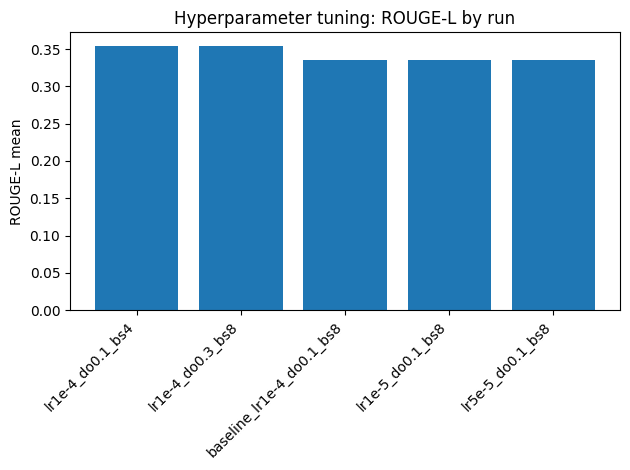

In [20]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(df_small["run"], df_small["rougeL_mean"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("ROUGE-L mean")
plt.title("Hyperparameter tuning: ROUGE-L by run")
plt.tight_layout()
plt.show()

13 — Plot diversity (unique preds) across runs

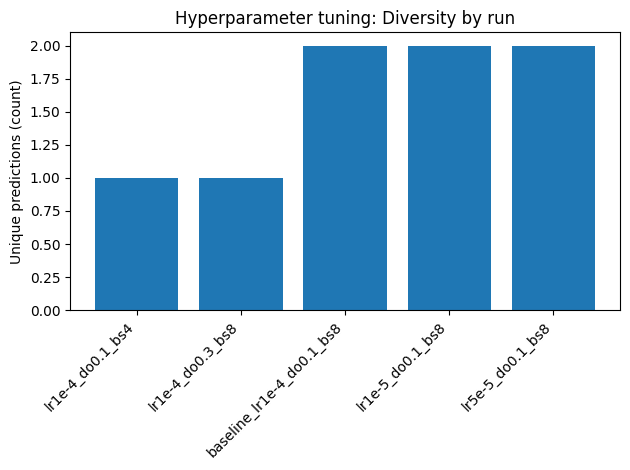

In [22]:
plt.figure()
plt.bar(df_small["run"], df_small["pred_unique"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Unique predictions (count)")
plt.title("Hyperparameter tuning: Diversity by run")
plt.tight_layout()
plt.show()

14 — Create a balanced score (ROUGE + diversity)

In [23]:
# Balanced score = ROUGE-L * (unique_preds / total_preds)
# (so a run with 1 unique pred is penalized heavily)
TOTAL_TEST = 44

df_small["diversity_ratio"] = df_small["pred_unique"] / TOTAL_TEST
df_small["balanced_score"] = df_small["rougeL_mean"] * df_small["diversity_ratio"]

df_small.sort_values("balanced_score", ascending=False)

,run,lr,dropout,batch_size,epochs,rougeL_mean,pred_unique,diversity_ratio,balanced_score
2,baseline_lr1e-4_do0.1_bs8,0.00010,0.1,8,3,0.335367,2,0.045455,0.015244
4,lr5e-5_do0.1_bs8,0.00005,0.1,8,3,0.335367,2,0.045455,0.015244
3,lr1e-5_do0.1_bs8,0.00001,0.1,8,3,0.335367,2,0.045455,0.015244
0,lr1e-4_do0.1_bs4,0.00010,0.1,4,3,0.354755,1,0.022727,0.008063
1,lr1e-4_do0.3_bs8,0.00010,0.3,8,3,0.354755,1,0.022727,0.008063


15 — Choose best run for final model

In [24]:
best = df_small.sort_values("balanced_score", ascending=False).iloc[0]
best

run                baseline_lr1e-4_do0.1_bs8
lr                                    0.0001
dropout                                  0.1
batch_size                                 8
epochs                                     3
rougeL_mean                         0.335367
pred_unique                                2
diversity_ratio                     0.045455
balanced_score                      0.015244
Name: 2, dtype: object

Final Model

In [1]:
!cd /home/psivakumar/thesis/code/R2GenCMN && python main.py \
  --dataset_name iu_xray \
  --image_dir /home/psivakumar/thesis/code/R2GenCMN/data/iu_xray \
  --ann_path /home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json \
  --save_dir /home/psivakumar/thesis/code/R2GenCMN/outputs/final_r2gencmn_10ep \
  --record_dir /home/psivakumar/thesis/code/R2GenCMN/records/final_r2gencmn_10ep \
  --epochs 10 \
  --batch_size 8 \
  --drop_prob_lm 0.1 \
  --dropout 0.1

/home/psivakumar/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/psivakumar/envs/ml/lib/python3.10/site-packages/torch/cuda/__init__.py:734: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
01/09/2026 20:54:15 - INFO - modules.trainer -   [1/10] Start to train in the training set.
01/09/2026 20:54:18 - INFO - modules.trainer -   [1/10] Step: 0/267, Training Loss: 6.96306.
01/0